# 6. Variance Reduction: Antithetic Variates

*Part 6 of **Stochastic Modelling and Monte Carlo Methods for Financial Markets**.*

Notebook 5 showed that the Monte Carlo error is $\sigma_f/\sqrt{N}$ and that the $N^{-1/2}$ rate is fixed. The other lever is the constant: an estimator of the **same** quantity whose samples have smaller variance needs proportionally fewer simulations for the same accuracy.

### Antithetic variates

If $Z \sim \mathcal{N}(0,1)$ then $-Z \sim \mathcal{N}(0,1)$ as well. Each draw is paired with its mirror image, and the two payoffs are averaged:

$$
Y_i = \frac{f(Z_i) + f(-Z_i)}{2}, \qquad \hat\theta^{\text{AV}} = \frac{1}{N/2}\sum_{i=1}^{N/2} Y_i.
$$

- **Unbiased**: $\mathbb{E}[f(-Z)] = \mathbb{E}[f(Z)]$, so $\mathbb{E}[Y_i] = \theta$.
- **Variance**: with $\rho = \operatorname{Corr}\big(f(Z), f(-Z)\big)$,

$$
\operatorname{Var}(Y_i) = \frac{\sigma_f^2}{2}(1 + \rho).
$$

At an equal budget of $N$ payoff evaluations ($N/2$ pairs), the plain estimator has variance $\sigma_f^2/N$ and the antithetic one has variance $\sigma_f^2(1+\rho)/N$. The **variance reduction factor** is

$$
\frac{\operatorname{Var}(\hat\theta^{\text{plain}})}{\operatorname{Var}(\hat\theta^{\text{AV}})} = \frac{1}{1+\rho}.
$$

The method helps exactly when $\rho < 0$. That is guaranteed when $f$ is a **monotone** function of $Z$, as for calls and puts, since $S_T$ increases with $Z$.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Make the project's src/ package importable when running from notebooks/
sys.path.insert(0, str(Path.cwd().parent / "src"))

from stochmc import (
    black_scholes_price,
    european_payoff,
    gbm_terminal_prices,
    price_european_option_mc,
)

SEED = 42
rng = np.random.default_rng(SEED)

FIGURES_DIR = Path.cwd().parent / "figures"
FIGURES_DIR.mkdir(exist_ok=True)

In [2]:
initial_price = 100
strike_price = 100
risk_free_rate = 0.05
annual_volatility = 0.20
time_to_maturity = 1

discount_factor = np.exp(-risk_free_rate * time_to_maturity)

option_parameters = dict(
    initial_price=initial_price,
    strike_price=strike_price,
    risk_free_rate=risk_free_rate,
    volatility=annual_volatility,
    time_to_maturity=time_to_maturity,
)

exact_call = black_scholes_price(
    initial_price, strike_price, risk_free_rate, annual_volatility, time_to_maturity, "call"
)


def discounted_payoff_from_shocks(normal_shocks, payoff_function):
    """Map standard normal shocks to discounted payoffs under the risk-neutral measure."""
    terminal_prices = gbm_terminal_prices(
        initial_price, risk_free_rate, annual_volatility, time_to_maturity, normal_shocks
    )
    return discount_factor * payoff_function(terminal_prices)


def call_payoff(terminal_prices, strike=strike_price):
    return european_payoff(terminal_prices, strike, "call")

## 6.1 Why the mirrored payoffs are negatively correlated

When $Z$ is large, $S_T$ is high and the call pays a lot, while $-Z$ gives a low $S_T$ and a small or zero payoff. Each pair therefore mixes a high and a low outcome, and their average is much less variable than either payoff alone.

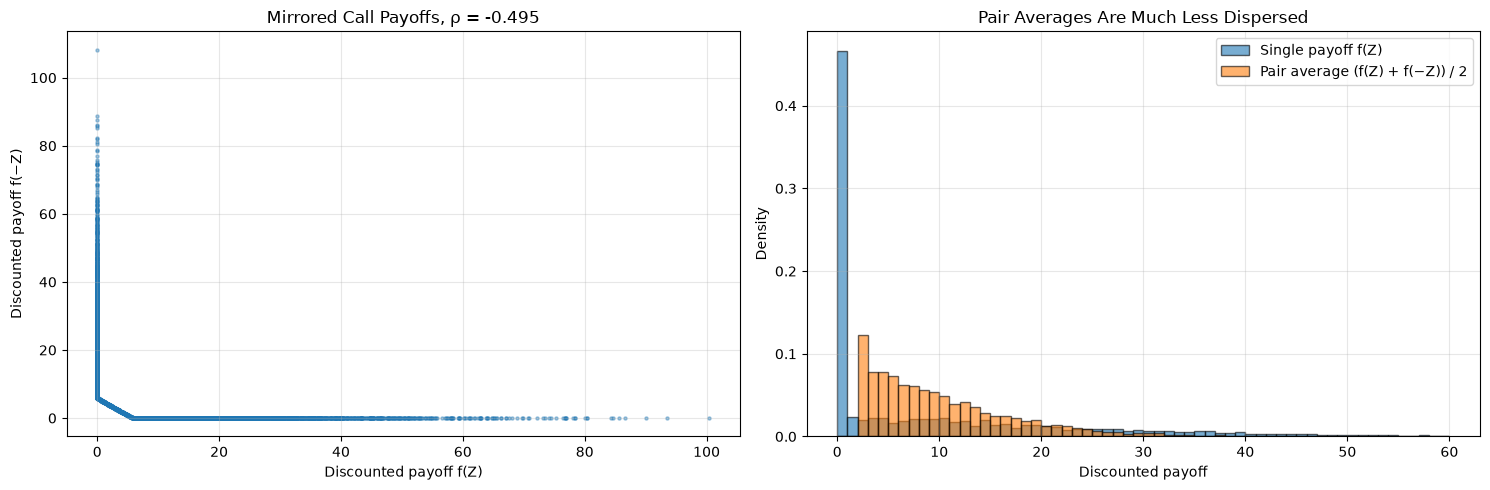

correlation_rho                           -0.494781
variance_single_payoff                   211.892872
variance_pair_average                     54.990627
theoretical_pair_variance (σ²/2)(1+ρ)     53.526194
variance_reduction_factor 1/(1+ρ)          1.979338
dtype: float64

In [3]:
n_pairs = 5_000

shocks = rng.standard_normal(n_pairs)
payoffs_plus = discounted_payoff_from_shocks(shocks, call_payoff)
payoffs_minus = discounted_payoff_from_shocks(-shocks, call_payoff)
pair_means = 0.5 * (payoffs_plus + payoffs_minus)

antithetic_correlation = np.corrcoef(payoffs_plus, payoffs_minus)[0, 1]

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

axes[0].scatter(payoffs_plus, payoffs_minus, s=5, alpha=0.4)
axes[0].set_title(f"Mirrored Call Payoffs, ρ = {antithetic_correlation:.3f}")
axes[0].set_xlabel("Discounted payoff f(Z)")
axes[0].set_ylabel("Discounted payoff f(−Z)")

bins = np.linspace(0, 60, 61)
axes[1].hist(payoffs_plus, bins=bins, density=True, alpha=0.6, edgecolor="black", label="Single payoff f(Z)")
axes[1].hist(pair_means, bins=bins, density=True, alpha=0.6, edgecolor="black", label="Pair average (f(Z) + f(−Z)) / 2")
axes[1].set_title("Pair Averages Are Much Less Dispersed")
axes[1].set_xlabel("Discounted payoff")
axes[1].set_ylabel("Density")
axes[1].legend()

for ax in axes:
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

pd.Series({
    "correlation_rho": antithetic_correlation,
    "variance_single_payoff": payoffs_plus.var(ddof=1),
    "variance_pair_average": pair_means.var(ddof=1),
    "theoretical_pair_variance (σ²/2)(1+ρ)": 0.5 * payoffs_plus.var(ddof=1) * (1 + antithetic_correlation),
    "variance_reduction_factor 1/(1+ρ)": 1 / (1 + antithetic_correlation),
})

## 6.2 Same estimator, lower variance

Both estimators price the ATM call with the same number of payoff evaluations $N = 100{,}000$. The antithetic version draws only $50{,}000$ normal numbers.

In [4]:
n_samples = 100_000

plain = price_european_option_mc(**option_parameters, n_samples=n_samples, rng=rng, option_type="call")
antithetic = price_european_option_mc(
    **option_parameters, n_samples=n_samples, rng=rng, option_type="call", antithetic=True
)

single_run_comparison = pd.DataFrame({
    "estimate": [plain.estimate, antithetic.estimate],
    "standard_error": [plain.standard_error, antithetic.standard_error],
    "ci_95_low": [plain.confidence_interval[0], antithetic.confidence_interval[0]],
    "ci_95_high": [plain.confidence_interval[1], antithetic.confidence_interval[1]],
    "black_scholes": [exact_call, exact_call],
    "bs_inside_ci": [plain.contains(exact_call), antithetic.contains(exact_call)],
}, index=["Plain Monte Carlo", "Antithetic variates"])

print(f"Standard error ratio (plain / antithetic): {plain.standard_error / antithetic.standard_error:.2f}")
print(f"Implied variance reduction factor: {(plain.standard_error / antithetic.standard_error) ** 2:.2f}")
single_run_comparison

Standard error ratio (plain / antithetic): 1.41
Implied variance reduction factor: 2.00


,estimate,standard_error,ci_95_low,ci_95_high,black_scholes,bs_inside_ci
Plain Monte Carlo,10.424142,0.046816,10.332384,10.515899,10.450584,True
Antithetic variates,10.493006,0.033106,10.428119,10.557892,10.450584,True


Both intervals contain the Black–Scholes price, but the antithetic interval is clearly narrower. The variance reduction factor equals the multiple of plain simulations the antithetic estimator is worth: plain Monte Carlo would need that many times more samples for the same accuracy.

## 6.3 Distribution of the two estimators

As in Notebook 3, each estimator is run many times to look at its sampling distribution directly.

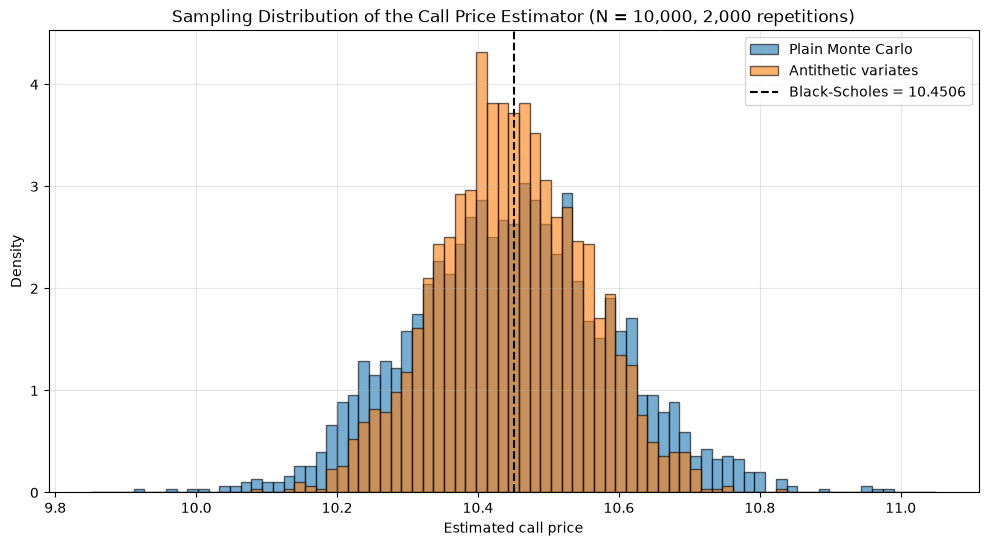

Empirical variance reduction factor: 1.90
Predicted from correlation, 1 / (1 + ρ): 1.98


,mean_estimate,bias,std_of_estimates,rmse
Plain Monte Carlo,10.447174,-0.003409,0.144469,0.144473
Antithetic variates,10.447687,-0.002897,0.104899,0.104913


In [5]:
n_samples = 10_000
n_repetitions = 2_000

plain_estimates = np.array([
    price_european_option_mc(**option_parameters, n_samples=n_samples, rng=rng).estimate
    for _ in range(n_repetitions)
])

antithetic_estimates = np.array([
    price_european_option_mc(**option_parameters, n_samples=n_samples, rng=rng, antithetic=True).estimate
    for _ in range(n_repetitions)
])

fig, ax = plt.subplots(figsize=(12, 6))

bins = np.linspace(exact_call - 0.6, exact_call + 0.6, 80)
ax.hist(plain_estimates, bins=bins, density=True, alpha=0.6, edgecolor="black", label="Plain Monte Carlo")
ax.hist(antithetic_estimates, bins=bins, density=True, alpha=0.6, edgecolor="black", label="Antithetic variates")
ax.axvline(exact_call, color="black", linestyle="--", label=f"Black-Scholes = {exact_call:.4f}")

ax.set_title(f"Sampling Distribution of the Call Price Estimator (N = {n_samples:,}, {n_repetitions:,} repetitions)")
ax.set_xlabel("Estimated call price")
ax.set_ylabel("Density")
ax.legend()
ax.grid(alpha=0.3)

plt.show()

distribution_comparison = pd.DataFrame({
    "mean_estimate": [plain_estimates.mean(), antithetic_estimates.mean()],
    "bias": [plain_estimates.mean() - exact_call, antithetic_estimates.mean() - exact_call],
    "std_of_estimates": [plain_estimates.std(ddof=1), antithetic_estimates.std(ddof=1)],
    "rmse": [
        np.sqrt(np.mean((plain_estimates - exact_call) ** 2)),
        np.sqrt(np.mean((antithetic_estimates - exact_call) ** 2)),
    ],
}, index=["Plain Monte Carlo", "Antithetic variates"])

empirical_variance_reduction = plain_estimates.var(ddof=1) / antithetic_estimates.var(ddof=1)

print(f"Empirical variance reduction factor: {empirical_variance_reduction:.2f}")
print(f"Predicted from correlation, 1 / (1 + ρ): {1 / (1 + antithetic_correlation):.2f}")
distribution_comparison

Both distributions are centred on the true price, so antithetic sampling adds no bias. The antithetic distribution is much narrower, and the empirical variance ratio matches the $1/(1+\rho)$ prediction from §6.1.

## 6.4 Convergence: same rate, smaller constant

Variance reduction does not change the $N^{-1/2}$ rate. It shifts the error curve down by a constant factor of $\sqrt{1+\rho}$.

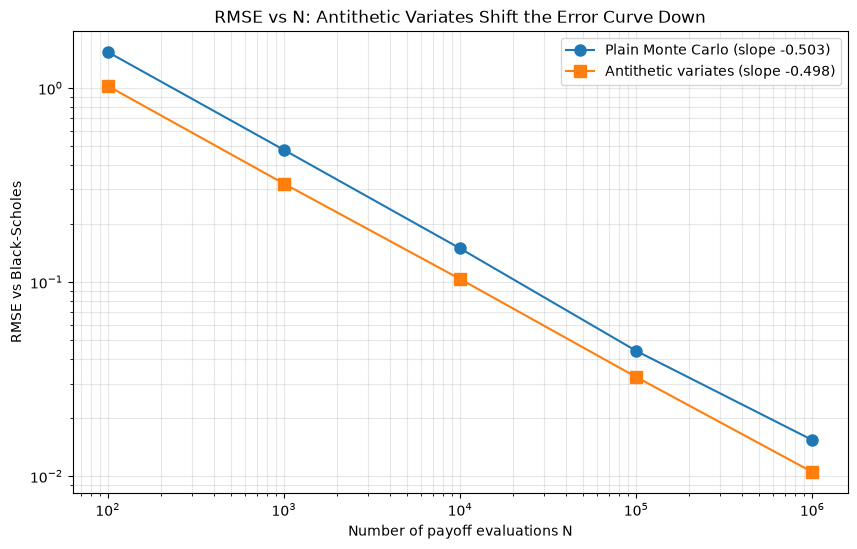

method,Antithetic variates,Plain Monte Carlo,rmse_ratio
N,,,
100,1.024192,1.531671,1.495491
1000,0.321396,0.479548,1.492082
10000,0.103612,0.149021,1.438251
100000,0.032393,0.044169,1.363561
1000000,0.010493,0.015336,1.461597


In [6]:
sample_sizes = np.array([10**2, 10**3, 10**4, 10**5, 10**6])
n_repetitions = 200

rmse_rows = []

for n in sample_sizes:
    for method, use_antithetic in [("Plain Monte Carlo", False), ("Antithetic variates", True)]:
        errors = np.array([
            price_european_option_mc(**option_parameters, n_samples=int(n), rng=rng, antithetic=use_antithetic).estimate
            - exact_call
            for _ in range(n_repetitions)
        ])
        rmse_rows.append({"N": n, "method": method, "rmse": np.sqrt(np.mean(errors**2))})

rmse_table = pd.DataFrame(rmse_rows).pivot(index="N", columns="method", values="rmse")
rmse_table["rmse_ratio"] = rmse_table["Plain Monte Carlo"] / rmse_table["Antithetic variates"]

fitted_slopes = {
    method: np.polyfit(np.log(rmse_table.index), np.log(rmse_table[method]), 1)[0]
    for method in ["Plain Monte Carlo", "Antithetic variates"]
}

fig, ax = plt.subplots(figsize=(10, 6))

for method, marker in [("Plain Monte Carlo", "o"), ("Antithetic variates", "s")]:
    ax.loglog(
        rmse_table.index,
        rmse_table[method],
        marker=marker,
        markersize=8,
        linewidth=1.5,
        label=f"{method} (slope {fitted_slopes[method]:.3f})"
    )

ax.set_title("RMSE vs N: Antithetic Variates Shift the Error Curve Down")
ax.set_xlabel("Number of payoff evaluations N")
ax.set_ylabel("RMSE vs Black-Scholes")
ax.legend()
ax.grid(alpha=0.3, which="both")

fig.savefig(FIGURES_DIR / "variance_reduction.png", dpi=150, bbox_inches="tight")
plt.show()

rmse_table

## 6.5 When does it help, and when does it not?

The gain depends on $\rho$, which depends on the payoff:

- **Deep in-the-money calls** have payoffs nearly linear in $S_T$, so $\rho \approx -1$ and the gain is very large.
- **Deep out-of-the-money calls** pay zero on most paths and on almost all mirrored paths, so $\rho \approx 0$ and the gain is small.
- **Non-monotone payoffs** such as a near-the-money straddle $|S_T - K|$ pay well for large $|Z|$ of either sign, so $f(Z)$ and $f(-Z)$ move *together*. Then $\rho > 0$ and antithetic sampling is **worse** than plain Monte Carlo. Far from the money the straddle behaves like a call or a put and becomes monotone over most of the distribution again.

The correlation is estimated across strikes from one large set of shocks.

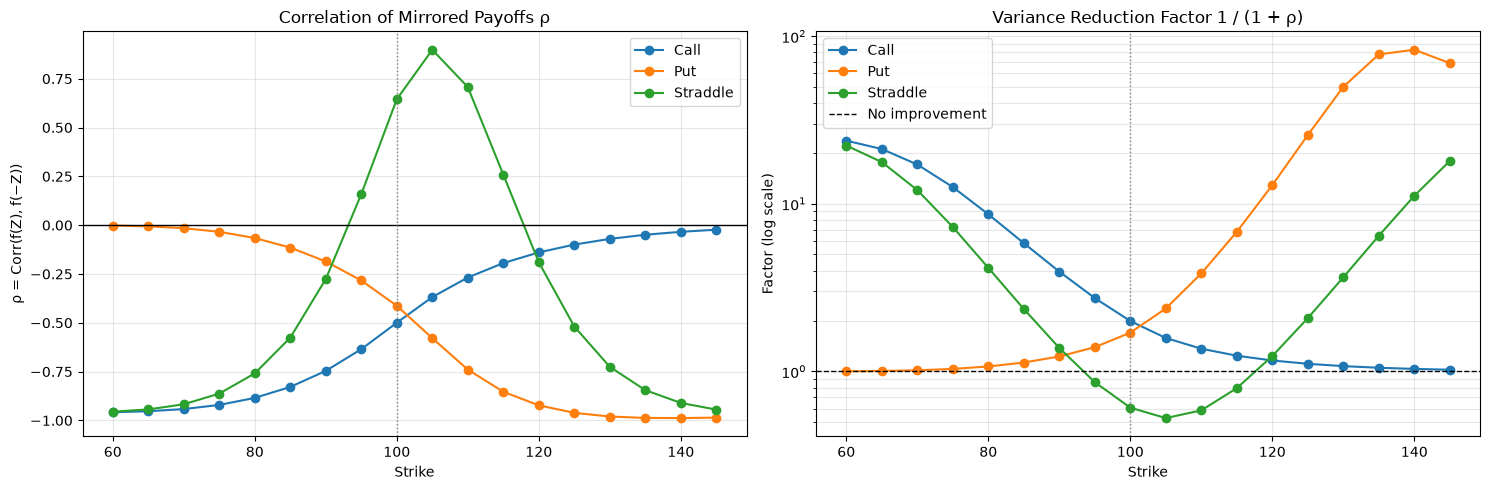

payoff,Call,Put,Straddle
strike,,,
60,23.818051,1.001918,22.267447
80,8.664285,1.070349,4.150477
100,1.998749,1.703146,0.607809
120,1.162079,12.924817,1.234960
145,1.023734,69.107305,18.022735


In [7]:
n_pairs = 200_000
shocks = rng.standard_normal(n_pairs)

payoff_definitions = {
    "Call": lambda s, k: np.maximum(s - k, 0),
    "Put": lambda s, k: np.maximum(k - s, 0),
    "Straddle": lambda s, k: np.abs(s - k),
}

strike_grid = np.arange(60, 150, 5)
moneyness_rows = []

for payoff_name, payoff_function in payoff_definitions.items():
    for strike in strike_grid:
        plus = discounted_payoff_from_shocks(shocks, lambda s: payoff_function(s, strike))
        minus = discounted_payoff_from_shocks(-shocks, lambda s: payoff_function(s, strike))

        rho = np.corrcoef(plus, minus)[0, 1]
        moneyness_rows.append({
            "payoff": payoff_name,
            "strike": strike,
            "rho": rho,
            "variance_reduction_factor": 1 / (1 + rho),
        })

moneyness = pd.DataFrame(moneyness_rows)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

for payoff_name, subset in moneyness.groupby("payoff", sort=False):
    axes[0].plot(subset["strike"], subset["rho"], "o-", label=payoff_name)
    axes[1].plot(subset["strike"], subset["variance_reduction_factor"], "o-", label=payoff_name)

axes[0].axhline(0, color="black", linewidth=1)
axes[0].set_title("Correlation of Mirrored Payoffs ρ")
axes[0].set_ylabel("ρ = Corr(f(Z), f(−Z))")

axes[1].axhline(1, color="black", linestyle="--", linewidth=1, label="No improvement")
axes[1].set_yscale("log")
axes[1].set_title("Variance Reduction Factor 1 / (1 + ρ)")
axes[1].set_ylabel("Factor (log scale)")

for ax in axes:
    ax.axvline(initial_price, color="grey", linestyle=":", linewidth=1)
    ax.set_xlabel("Strike")
    ax.legend()
    ax.grid(alpha=0.3, which="both")

plt.tight_layout()
plt.show()

moneyness.pivot(index="strike", columns="payoff", values="variance_reduction_factor").loc[[60, 80, 100, 120, 145]]

Antithetic variates are reliable for monotone payoffs, with the largest gains in the money. For the near-the-money straddle the factor drops below 1, so pairing *increases* variance. Before using a variance-reduction technique, check $\rho$ (or compare standard errors) on a pilot run.

In [8]:
assert antithetic.standard_error < plain.standard_error
assert abs(distribution_comparison.loc["Antithetic variates", "bias"]) < 4 * antithetic_estimates.std(ddof=1) / np.sqrt(len(antithetic_estimates))
assert empirical_variance_reduction > 1.5
assert all(abs(slope + 0.5) < 0.1 for slope in fitted_slopes.values())
assert (moneyness.query("payoff == 'Straddle' and strike == 100")["rho"] > 0).all()

print("Variance reduction checks passed.")

Variance reduction checks passed.


## Conclusions

- Antithetic variates pair each normal draw $Z$ with $-Z$. The estimator stays **unbiased**, and its variance is multiplied by $(1+\rho)$.
- For the ATM European call, $\rho \approx -0.5$ and the variance roughly halves. The same accuracy needs about half the payoff evaluations and a quarter of the random numbers. Deep in-the-money options gain far more (factors of 20–80).
- The convergence rate is still $N^{-1/2}$; only the constant improves.
- The gain depends on the payoff: largest for near-linear (deep ITM) payoffs, small for deep OTM, and **negative** for non-monotone payoffs such as straddles.

### Where to go next

- **Control variates**: use $S_T$ (whose discounted mean $S_0$ is known) to correct the estimate. For deep ITM options this removes almost all variance.
- **Importance sampling**: shift the sampling distribution towards the region where the payoff is non-zero, which helps deep OTM options most.
- **Quasi-Monte Carlo**: low-discrepancy sequences (Sobol) can beat the $N^{-1/2}$ rate for smooth, low-dimensional problems.
- **Path-dependent payoffs** (Asian, barrier, lookback), where no closed form exists and Monte Carlo is the method of choice.